In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")

PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 10.3 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

print("Ultralytics YOLO installed successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics YOLO installed successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Microplastic_Project/Dataset"

print("Dataset exists:", os.path.exists(dataset_path))
print("\nFolders found:")

for item in os.listdir(dataset_path):
    print("-", item)

Dataset exists: True

Folders found:
- test_images
- test_labels
- train_images
- train_labels
- val_images
- val_labels


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Microplastic_Project/Dataset"

folders = [
    "train_images",
    "train_labels",
    "val_images",
    "val_labels",
    "test_images",
    "test_labels"
]

for folder in folders:
    folder_path = os.path.join(dataset_path, folder)
    files = os.listdir(folder_path)

    if "images" in folder:
        files = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    else:
        files = [f for f in files if f.lower().endswith(".txt")]

    print(f"{folder}: {len(files)}")

train_images: 0
train_labels: 0
val_images: 0
val_labels: 0
test_images: 0
test_labels: 0


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Microplastic_Project/Dataset"

for folder in ["train_images", "train_labels", "val_images", "val_labels", "test_images", "test_labels"]:
    folder_path = os.path.join(dataset_path, folder)

    all_files = []
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            all_files.append(os.path.join(root, file))

    print("\n" + folder)
    print("Total files found:", len(all_files))

    if all_files:
        print("First 3 files:")
        for f in all_files[:3]:
            print(" ", f)


train_images
Total files found: 1990
First 3 files:
  /content/drive/MyDrive/Microplastic_Project/Dataset/train_images/train_images/train_1890.jpg
  /content/drive/MyDrive/Microplastic_Project/Dataset/train_images/train_images/train_1891.jpg
  /content/drive/MyDrive/Microplastic_Project/Dataset/train_images/train_images/train_1892.jpg

train_labels
Total files found: 1990
First 3 files:
  /content/drive/MyDrive/Microplastic_Project/Dataset/train_labels/train_labels/train_1890.txt
  /content/drive/MyDrive/Microplastic_Project/Dataset/train_labels/train_labels/train_1891.txt
  /content/drive/MyDrive/Microplastic_Project/Dataset/train_labels/train_labels/train_1892.txt

val_images
Total files found: 250
First 3 files:
  /content/drive/MyDrive/Microplastic_Project/Dataset/val_images/val_images/val_1.jpg
  /content/drive/MyDrive/Microplastic_Project/Dataset/val_images/val_images/val_10.jpg
  /content/drive/MyDrive/Microplastic_Project/Dataset/val_images/val_images/val_100.jpg

val_labels
T

In [ ]:
import os

base = "/content/drive/MyDrive/Microplastic_Project/Dataset"

splits = {
    "train": (
        os.path.join(base, "train_images", "train_images"),
        os.path.join(base, "train_labels", "train_labels")
    ),
    "val": (
        os.path.join(base, "val_images", "val_images"),
        os.path.join(base, "val_labels", "val_labels")
    ),
    "test": (
        os.path.join(base, "test_images", "test_images"),
        os.path.join(base, "test_labels", "test_labels")
    )
}

for split, (image_dir, label_dir) in splits.items():

    images = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    labels = {
        os.path.splitext(f)[0]
        for f in os.listdir(label_dir)
        if f.lower().endswith(".txt")
    }

    missing_labels = images - labels
    missing_images = labels - images

    print(f"\n{split.upper()} SET")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(missing_images))

    if not missing_labels and not missing_images:
        print("✅ Perfect match")
    else:
        print("⚠️ Mismatch found")


TRAIN SET
Images: 1990
Labels: 1990
Images without labels: 0
Labels without images: 0
✅ Perfect match

VAL SET
Images: 250
Labels: 250
Images without labels: 0
Labels without images: 0
✅ Perfect match

TEST SET
Images: 250
Labels: 250
Images without labels: 0
Labels without images: 0
✅ Perfect match


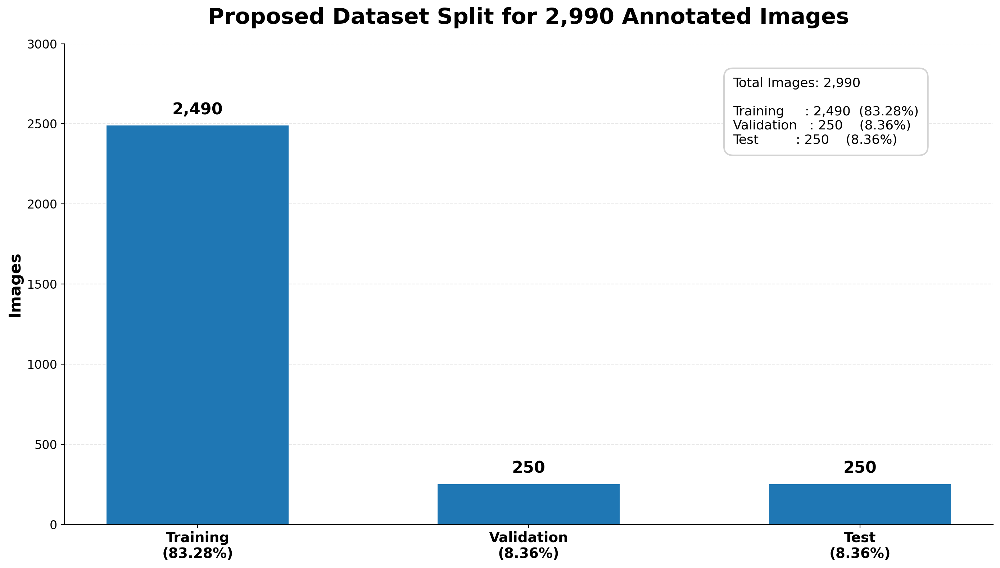

In [ ]:
import matplotlib.pyplot as plt

# Dataset values
labels = ["Training", "Validation", "Test"]
values = [2490, 250, 250]
total = sum(values)

# Calculate percentages
percentages = [(v / total) * 100 for v in values]

# Create figure
fig, ax = plt.subplots(figsize=(14, 8), dpi=200)

# Bars
bars = ax.bar(
    labels,
    values,
    width=0.55
)

# Title
ax.set_title(
    f"Proposed Dataset Split for {total:,} Annotated Images",
    fontsize=22,
    fontweight="bold",
    pad=20
)

# Y-axis
ax.set_ylabel("Images", fontsize=16, fontweight="bold")
ax.set_ylim(0, 3000)
ax.set_yticks(range(0, 3001, 500))
ax.tick_params(axis="y", labelsize=12)

# X-axis labels with percentages
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(
    [
        f"Training\n({percentages[0]:.2f}%)",
        f"Validation\n({percentages[1]:.2f}%)",
        f"Test\n({percentages[2]:.2f}%)"
    ],
    fontsize=14,
    fontweight="bold"
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)
ax.set_axisbelow(True)

# Value labels above bars
for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 50,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold"
    )

# Summary box
summary = (
    f"Total Images: {total:,}\n\n"
    f"Training     : {values[0]:,}  ({percentages[0]:.2f}%)\n"
    f"Validation   : {values[1]:,}    ({percentages[1]:.2f}%)\n"
    f"Test         : {values[2]:,}    ({percentages[2]:.2f}%)"
)

ax.text(
    0.72,
    0.93,
    summary,
    transform=ax.transAxes,
    fontsize=13,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.7",
        facecolor="white",
        edgecolor="lightgray",
        linewidth=1.5
    )
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Adjust layout
plt.tight_layout()

# Save high-resolution image
plt.savefig(
    "proposed_dataset_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import os
import shutil

source = "/content/drive/MyDrive/Microplastic_Project/Dataset"
target = "/content/Microplastic_YOLO_Dataset"

# Create YOLO folder structure
folders = [
    "images/train",
    "images/val",
    "images/test",
    "labels/train",
    "labels/val",
    "labels/test"
]

for folder in folders:
    os.makedirs(os.path.join(target, folder), exist_ok=True)

# Source → target mapping
mapping = {
    "train": ("train_images/train_images", "train_labels/train_labels"),
    "val": ("val_images/val_images", "val_labels/val_labels"),
    "test": ("test_images/test_images", "test_labels/test_labels")
}

for split, (image_folder, label_folder) in mapping.items():

    image_source = os.path.join(source, image_folder)
    label_source = os.path.join(source, label_folder)

    image_target = os.path.join(target, "images", split)
    label_target = os.path.join(target, "labels", split)

    for file in os.listdir(image_source):
        shutil.copy2(
            os.path.join(image_source, file),
            os.path.join(image_target, file)
        )

    for file in os.listdir(label_source):
        shutil.copy2(
            os.path.join(label_source, file),
            os.path.join(label_target, file)
        )

    print(f"{split} set copied successfully.")

print("\nYOLO dataset created at:")
print(target)

train set copied successfully.
val set copied successfully.
test set copied successfully.

YOLO dataset created at:
/content/Microplastic_YOLO_Dataset


In [ ]:
data_yaml = """
path: /content/Microplastic_YOLO_Dataset

train: images/train
val: images/val
test: images/test

names:
  0: microplastic
"""

with open("/content/Microplastic_YOLO_Dataset/data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml created successfully!")

data.yaml created successfully!


In [ ]:
with open("/content/Microplastic_YOLO_Dataset/data.yaml", "r") as f:
    print(f.read())


path: /content/Microplastic_YOLO_Dataset

train: images/train
val: images/val
test: images/test

names:
  0: microplastic



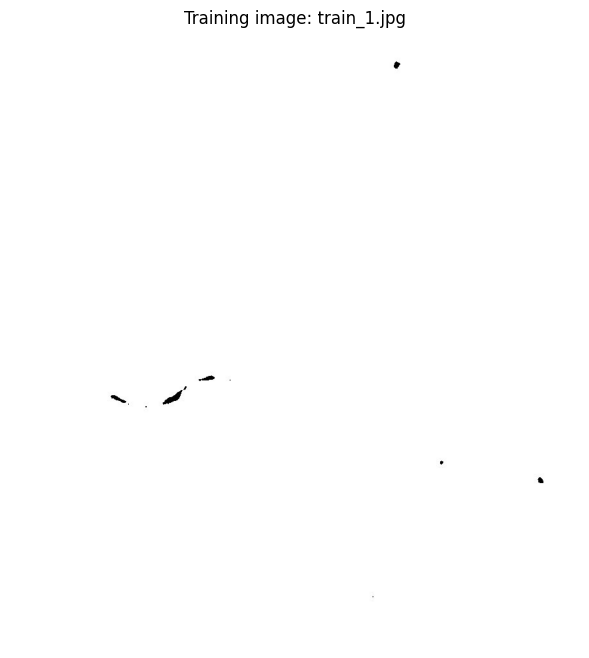

Image: train_1.jpg
Label file: train_1.txt

YOLO annotations:
0 0.6351351351351351 0.9166666666666666 0.009009009009009009 0.016666666666666666
0 0.9279279279279279 0.725 0.018018018018018018 0.016666666666666666
0 0.7567567567567568 0.7 0.018018018018018018 0.016666666666666666
0 0.23873873873873874 0.6083333333333333 0.009009009009009009 0.016666666666666666
0 0.19256756756756757 0.596875 0.05630630630630631 0.041666666666666664
0 0.28885135135135137 0.5927083333333333 0.0686936936936937 0.04791666666666667
0 0.34234234234234234 0.5583333333333333 0.036036036036036036 0.016666666666666666
0 0.6756756756756757 0.05416666666666667 0.018018018018018018 0.025


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_dir = "/content/Microplastic_YOLO_Dataset/images/train"
label_dir = "/content/Microplastic_YOLO_Dataset/labels/train"

# Select the first training image
image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_name = image_files[0]

image_path = os.path.join(image_dir, image_name)
label_path = os.path.join(
    label_dir,
    os.path.splitext(image_name)[0] + ".txt"
)

img = Image.open(image_path).convert("RGB")

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.title(f"Training image: {image_name}")
plt.show()

print("Image:", image_name)
print("Label file:", os.path.basename(label_path))

with open(label_path, "r") as f:
    print("\nYOLO annotations:")
    print(f.read())

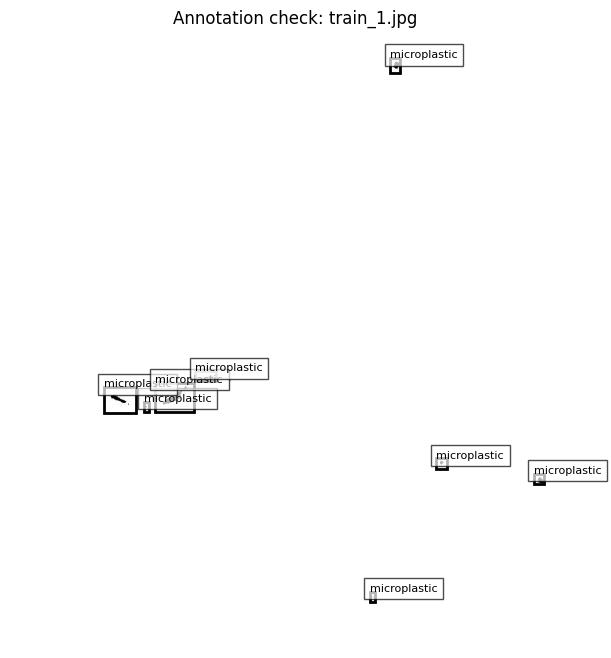

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_dir = "/content/Microplastic_YOLO_Dataset/images/train"
label_dir = "/content/Microplastic_YOLO_Dataset/labels/train"

image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_name = image_files[0]

image_path = os.path.join(image_dir, image_name)
label_path = os.path.join(
    label_dir,
    os.path.splitext(image_name)[0] + ".txt"
)

img = Image.open(image_path).convert("RGB")
img_width, img_height = img.size

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

with open(label_path, "r") as f:
    for line in f:
        values = line.strip().split()

        if len(values) != 5:
            continue

        class_id, x_center, y_center, width, height = map(float, values)

        # Convert normalized YOLO coordinates to pixels
        x_center *= img_width
        y_center *= img_height
        width *= img_width
        height *= img_height

        x = x_center - width / 2
        y = y_center - height / 2

        rectangle = plt.Rectangle(
            (x, y),
            width,
            height,
            fill=False,
            linewidth=2
        )

        ax.add_patch(rectangle)
        ax.text(
            x,
            y,
            "microplastic",
            fontsize=8,
            bbox=dict(facecolor="white", alpha=0.7)
        )

ax.axis("off")
ax.set_title(f"Annotation check: {image_name}")
plt.show()

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 10.6 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

print("Ultralytics imported successfully!")

model = YOLO("yolo11s.pt")

print("YOLO model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics imported successfully!
YOLO model loaded successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print("Microplastic_Project contents:")
print(os.listdir("/content/drive/MyDrive/Microplastic_Project"))

Microplastic_Project contents:
['Dataset']


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Microplastic_Project/Dataset"

print("Dataset contents:")
for item in os.listdir(dataset_path):
    print(item)

Dataset contents:
test_images
test_labels
train_images
train_labels
val_images
val_labels


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Microplastic_Project/Dataset"

print("Dataset contents:")
for item in os.listdir(dataset_path):
    print("-", item)

Dataset contents:
- test_images
- test_labels
- train_images
- train_labels
- val_images
- val_labels


In [ ]:
import os
import shutil

source = "/content/drive/MyDrive/Microplastic_Project/Dataset"
target = "/content/Microplastic_YOLO_Dataset"

# Create YOLO structure
for folder in [
    "images/train", "images/val", "images/test",
    "labels/train", "labels/val", "labels/test"
]:
    os.makedirs(os.path.join(target, folder), exist_ok=True)

splits = {
    "train": ("train_images", "train_labels"),
    "val": ("val_images", "val_labels"),
    "test": ("test_images", "test_labels")
}

for split, (img_folder, lbl_folder) in splits.items():

    img_root = os.path.join(source, img_folder)
    lbl_root = os.path.join(source, lbl_folder)

    # Find all image files recursively
    image_files = []
    for root, dirs, files in os.walk(img_root):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                image_files.append(os.path.join(root, file))

    # Find all label files recursively
    label_files = []
    for root, dirs, files in os.walk(lbl_root):
        for file in files:
            if file.lower().endswith(".txt"):
                label_files.append(os.path.join(root, file))

    # Copy images
    for file_path in image_files:
        shutil.copy2(
            file_path,
            os.path.join(target, "images", split, os.path.basename(file_path))
        )

    # Copy labels
    for file_path in label_files:
        shutil.copy2(
            file_path,
            os.path.join(target, "labels", split, os.path.basename(file_path))
        )

    print(f"{split}: {len(image_files)} images, {len(label_files)} labels")

print("\nYOLO dataset recreated successfully!")

train: 1990 images, 1990 labels
val: 250 images, 250 labels
test: 250 images, 250 labels

YOLO dataset recreated successfully!


In [ ]:
import os

yaml_path = "/content/Microplastic_YOLO_Dataset/data.yaml"

print("data.yaml exists:", os.path.exists(yaml_path))

print("\nDataset folders:")
for folder in [
    "images/train",
    "images/val",
    "images/test",
    "labels/train",
    "labels/val",
    "labels/test"
]:
    path = os.path.join("/content/Microplastic_YOLO_Dataset", folder)
    print(folder, "->", len(os.listdir(path)), "files")

data.yaml exists: False

Dataset folders:
images/train -> 1990 files
images/val -> 250 files
images/test -> 250 files
labels/train -> 1990 files
labels/val -> 250 files
labels/test -> 250 files


In [ ]:
print(type(model))

<class 'ultralytics.models.yolo.model.YOLO'>


In [ ]:
results = model.train(
    data="/content/Microplastic_YOLO_Dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    device=0,
    project="/content/Microplastic_Results",
    name="yolo11s_baseline",
    plots=True
)

Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Microplastic_YOLO_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_baseline-2, nbs=64, nm

RuntimeError: Dataset '/content/Microplastic_YOLO_Dataset/data.yaml' error ❌ '/content/Microplastic_YOLO_Dataset/data.yaml' does not exist

In [ ]:
import os
import shutil

source = "/content/drive/MyDrive/Microplastic_Project/Dataset"
target = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset"

# Create folders
for folder in [
    "images/train",
    "images/val",
    "images/test",
    "labels/train",
    "labels/val",
    "labels/test"
]:
    os.makedirs(os.path.join(target, folder), exist_ok=True)

splits = {
    "train": ("train_images", "train_labels"),
    "val": ("val_images", "val_labels"),
    "test": ("test_images", "test_labels")
}

for split, (img_folder, lbl_folder) in splits.items():

    img_root = os.path.join(source, img_folder)
    lbl_root = os.path.join(source, lbl_folder)

    image_count = 0
    label_count = 0

    for root, dirs, files in os.walk(img_root):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                shutil.copy2(
                    os.path.join(root, file),
                    os.path.join(target, "images", split, file)
                )
                image_count += 1

    for root, dirs, files in os.walk(lbl_root):
        for file in files:
            if file.lower().endswith(".txt"):
                shutil.copy2(
                    os.path.join(root, file),
                    os.path.join(target, "labels", split, file)
                )
                label_count += 1

    print(f"{split}: {image_count} images, {label_count} labels")

print("\nPermanent YOLO dataset created!")
print(target)

train: 1990 images, 1990 labels
val: 250 images, 250 labels
test: 250 images, 250 labels

Permanent YOLO dataset created!
/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset


In [ ]:
data_yaml = """
path: /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset

train: images/train
val: images/val
test: images/test

names:
  0: microplastic
"""

yaml_path = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml"

with open(yaml_path, "w") as f:
    f.write(data_yaml)

print("Permanent data.yaml created!")
print(yaml_path)

Permanent data.yaml created!
/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml


In [ ]:
import os

yaml_path = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml"

print("YAML exists:", os.path.exists(yaml_path))

for split in ["train", "val", "test"]:
    images = os.listdir(
        f"/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/{split}"
    )
    labels = os.listdir(
        f"/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/labels/{split}"
    )

    print(f"{split}: {len(images)} images | {len(labels)} labels")

YAML exists: True
train: 1990 images | 1990 labels
val: 250 images | 250 labels
test: 250 images | 250 labels


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")
print("Model ready!")

Model ready!


In [ ]:
results = model.train(
    data="/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    device=0,
    project="/content/drive/MyDrive/Microplastic_Project/Results",
    name="yolo11s_baseline",
    plots=True
)

Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_

In [ ]:
from ultralytics import YOLO

best_model = YOLO(
    "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/weights/best.pt"
)

test_results = best_model.val(
    data="/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/Microplastic_Project/Results",
    name="yolo11s_test"
)

print("TEST EVALUATION COMPLETED")

Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.6 ms, read: 6.6±5.4 MB/s, size: 14.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/labels/test... 250 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 250/250 134.5it/s 1.9s
val: New cache created: /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.6it/s 9.9s
                   all        250        539      0.854      0.903      0.937      0.658
Speed: 5.9ms preprocess, 11.4ms inference, 0.0ms loss, 4.0ms postprocess per image
Results saved to /content/drive/MyD

In [ ]:
import os

results_path = "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline"

print("Files generated:")
for file in sorted(os.listdir(results_path)):
    print(file)

Files generated:
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights


In [ ]:
from ultralytics import YOLO

best_model = YOLO(
    "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/weights/best.pt"
)

test_images = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test"

predictions = best_model.predict(
    source=test_images,
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    save_txt=True,
    save_conf=True,
    project="/content/drive/MyDrive/Microplastic_Project/Results",
    name="test_predictions"
)

print("TEST PREDICTIONS GENERATED SUCCESSFULLY")


image 1/250 /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test/test_1.jpg: 640x608 2 microplastics, 15.1ms
image 2/250 /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test/test_10.jpg: 640x608 3 microplastics, 15.2ms
image 3/250 /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test/test_100.jpg: 640x608 8 microplastics, 15.2ms
image 4/250 /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test/test_101.jpg: 640x608 2 microplastics, 15.1ms
image 5/250 /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test/test_102.jpg: 640x608 2 microplastics, 15.1ms
image 6/250 /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test/test_103.jpg: 640x608 2 microplastics, 15.1ms
image 7/250 /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test/test_104.jpg: 640x608 1 microplastic, 15.2ms
image 8/250 /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test/test_105.jpg: 640x608 1 microplas

In [ ]:
import os

prediction_folder = "/content/drive/MyDrive/Microplastic_Project/Results/test_predictions"

images = [
    f for f in os.listdir(prediction_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Prediction images generated:", len(images))
print("First 10 predictions:")
print(images[:10])

Prediction images generated: 250
First 10 predictions:
['test_1.jpg', 'test_10.jpg', 'test_100.jpg', 'test_101.jpg', 'test_102.jpg', 'test_103.jpg', 'test_104.jpg', 'test_105.jpg', 'test_106.jpg', 'test_107.jpg']


In [ ]:
from ultralytics import YOLO

best_model = YOLO(
    "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/weights/best.pt"
)

test_results = best_model.val(
    data="/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("\n========== TEST RESULTS ==========")
print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP@50:", test_results.box.map50)
print("mAP@50-95:", test_results.box.map)

Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.3±0.0 ms, read: 18.3±5.6 MB/s, size: 14.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/labels/test.cache... 250 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 250/250 30.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 2.4it/s 6.7s
                   all        250        539      0.854      0.903      0.937      0.658
Speed: 3.7ms preprocess, 8.2ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs/detect/val

========== TEST RESULTS ==========
Precision: 0.854320545998466
Recall: 0.90305077863

In [ ]:
import os

results_path = "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline"

print("BASELINE RESULT FILES:\n")

for root, dirs, files in os.walk(results_path):
    for file in sorted(files):
        print(os.path.join(root, file))

BASELINE RESULT FILES:

/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/BoxF1_curve.png
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/BoxPR_curve.png
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/BoxP_curve.png
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/BoxR_curve.png
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/args.yaml
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/confusion_matrix.png
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/confusion_matrix_normalized.png
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/labels.jpg
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/results.csv
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/results.png
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/train_batch0.jpg
/content/drive/MyDrive/Microplastic_Proj


results.png


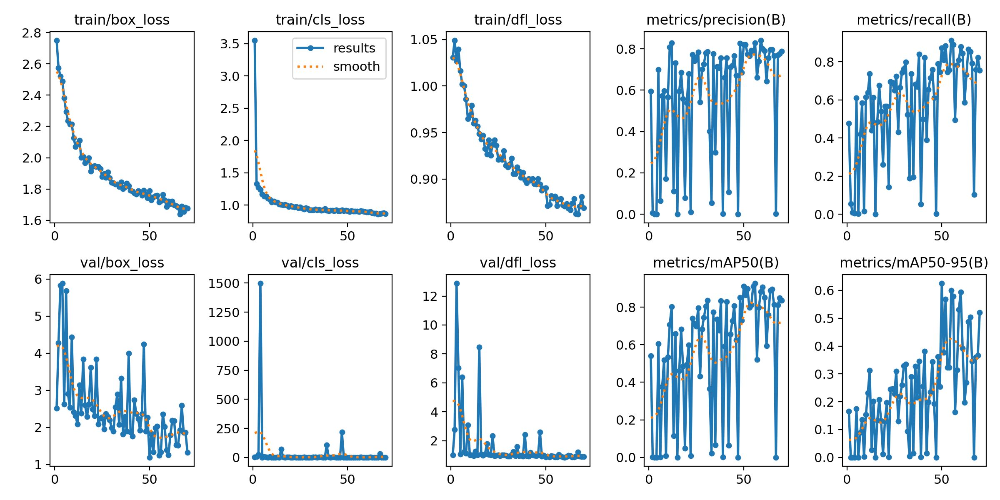


confusion_matrix.png


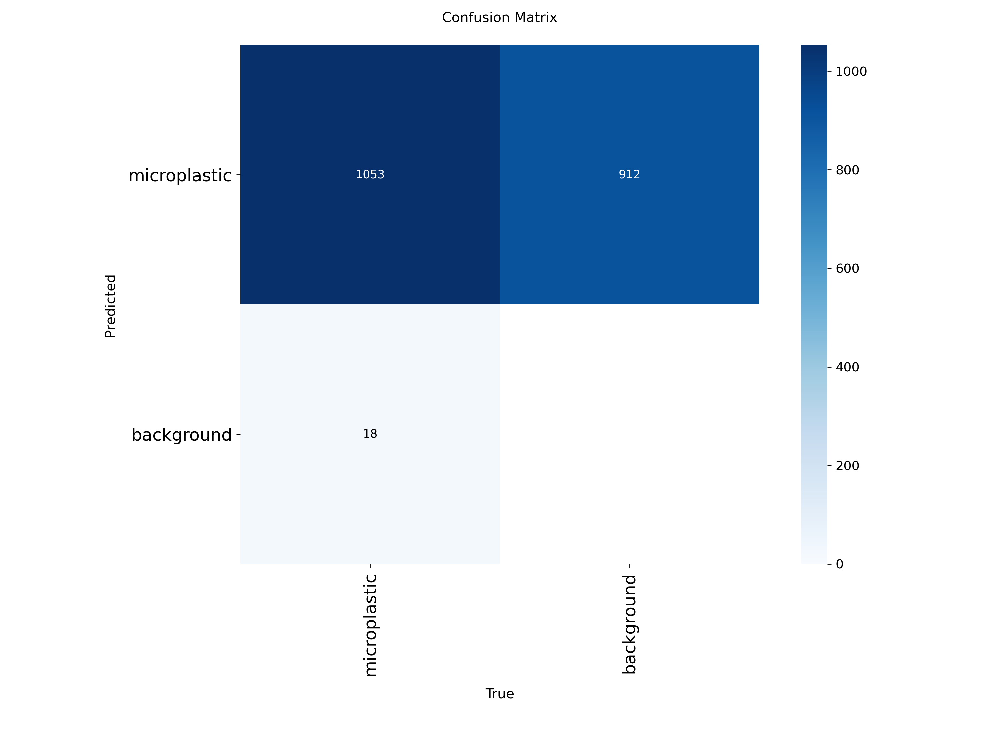


confusion_matrix_normalized.png


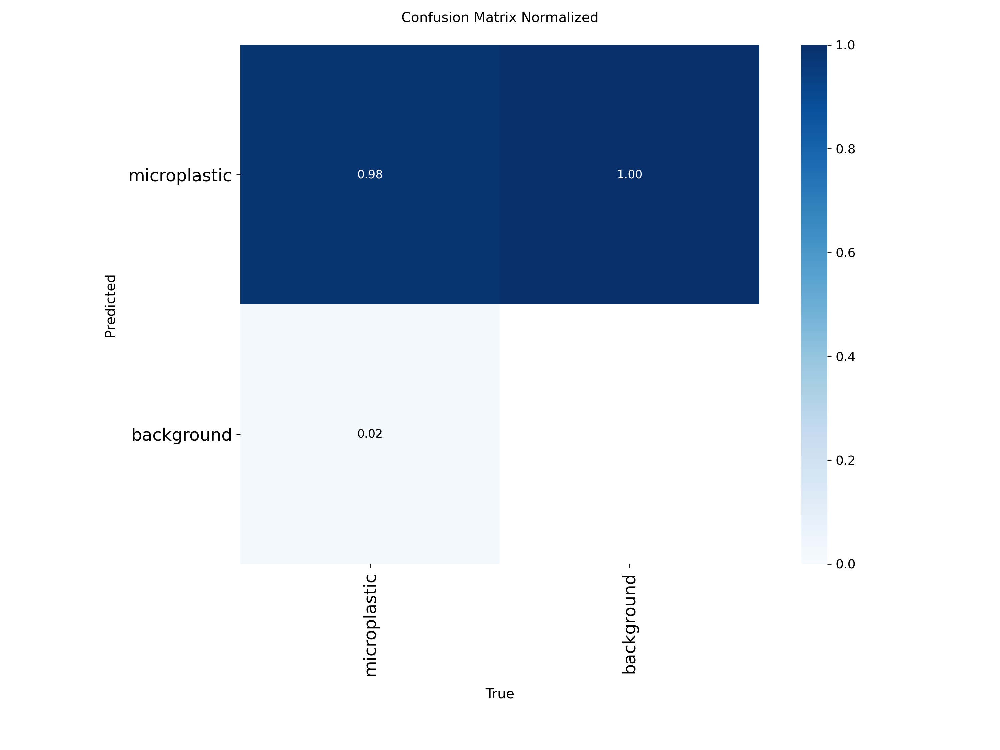

NOT FOUND: PR_curve.png
NOT FOUND: F1_curve.png
NOT FOUND: P_curve.png
NOT FOUND: R_curve.png


In [ ]:
from IPython.display import display
from PIL import Image
import os

results_path = "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline"

figures = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png"
]

for filename in figures:
    filepath = os.path.join(results_path, filename)

    if os.path.exists(filepath):
        print("\n" + "="*60)
        print(filename)
        display(Image.open(filepath))
    else:
        print("NOT FOUND:", filename)

In [ ]:
import os

test_path = "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_test"

print("TEST EVALUATION FILES:\n")

if os.path.exists(test_path):
    for root, dirs, files in os.walk(test_path):
        for file in sorted(files):
            print(os.path.relpath(os.path.join(root, file), test_path))
else:
    print("yolo11s_test folder not found")

TEST EVALUATION FILES:

BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg



BoxPR_curve.png


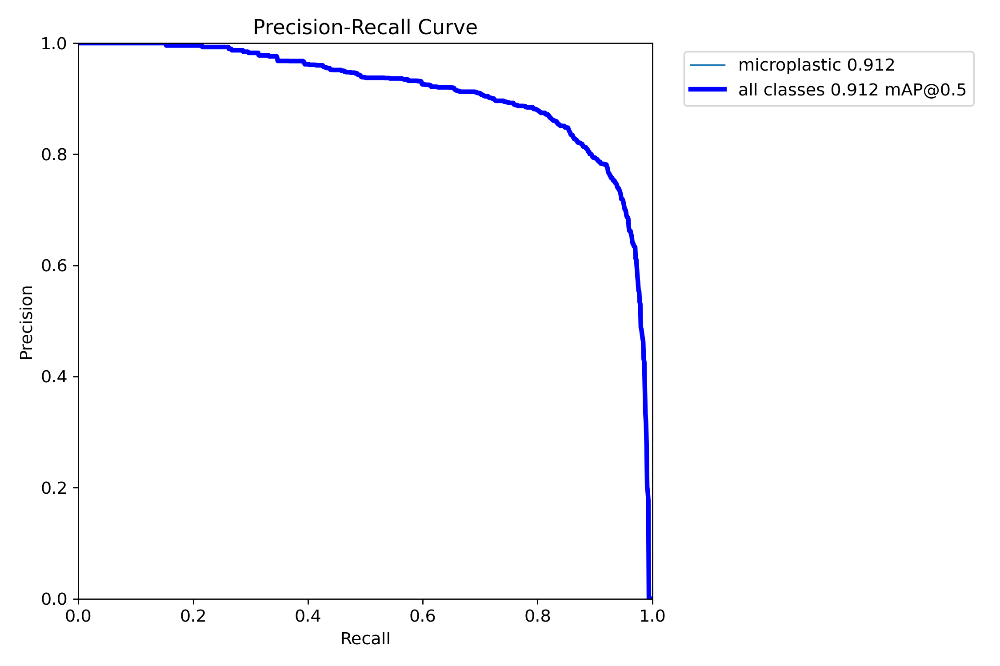


BoxF1_curve.png


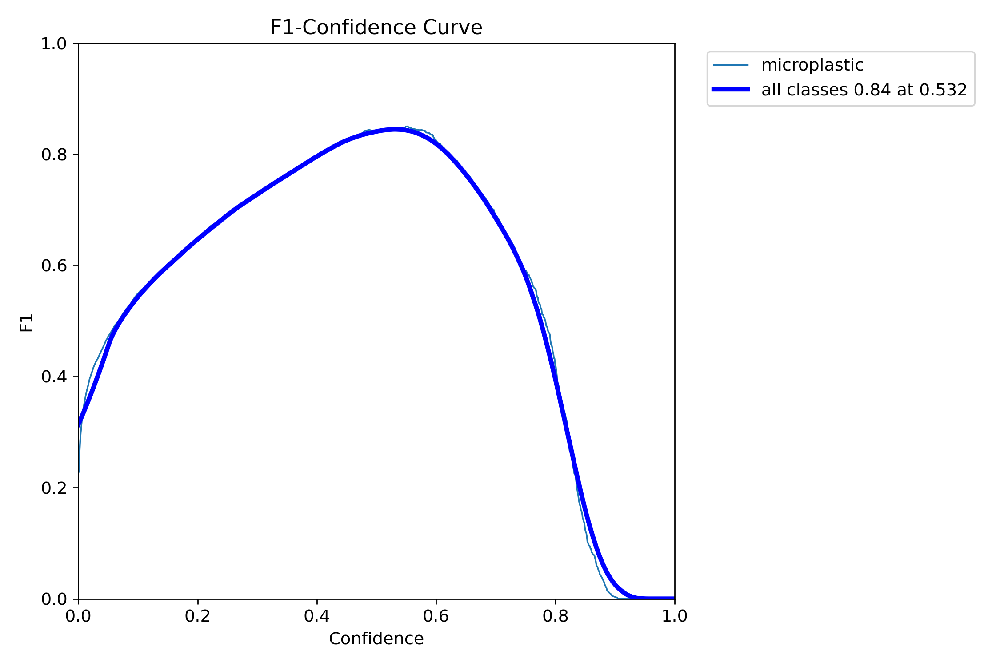


BoxP_curve.png


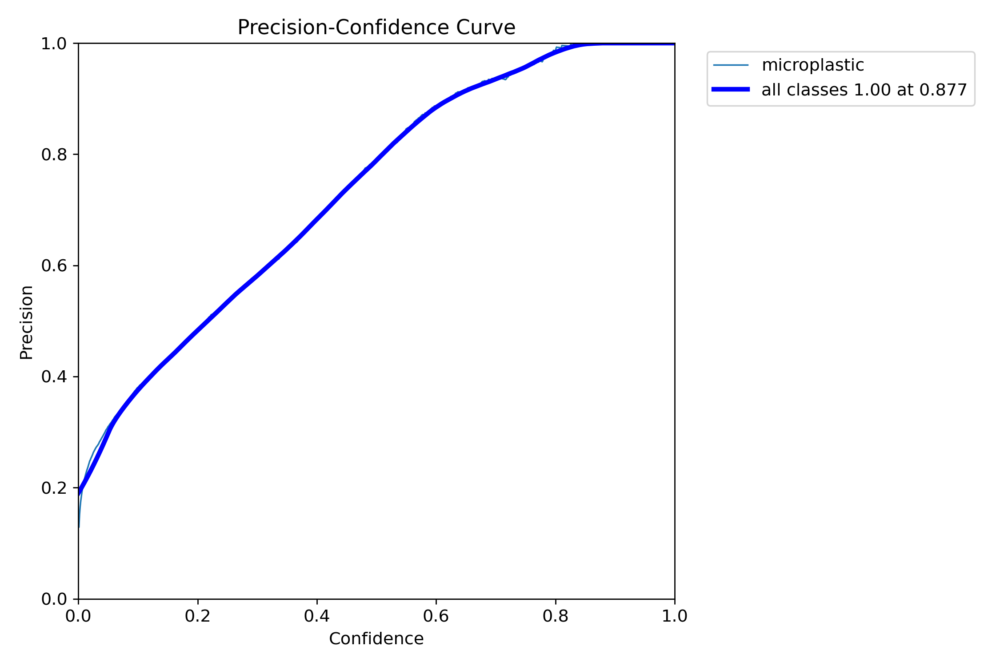


BoxR_curve.png


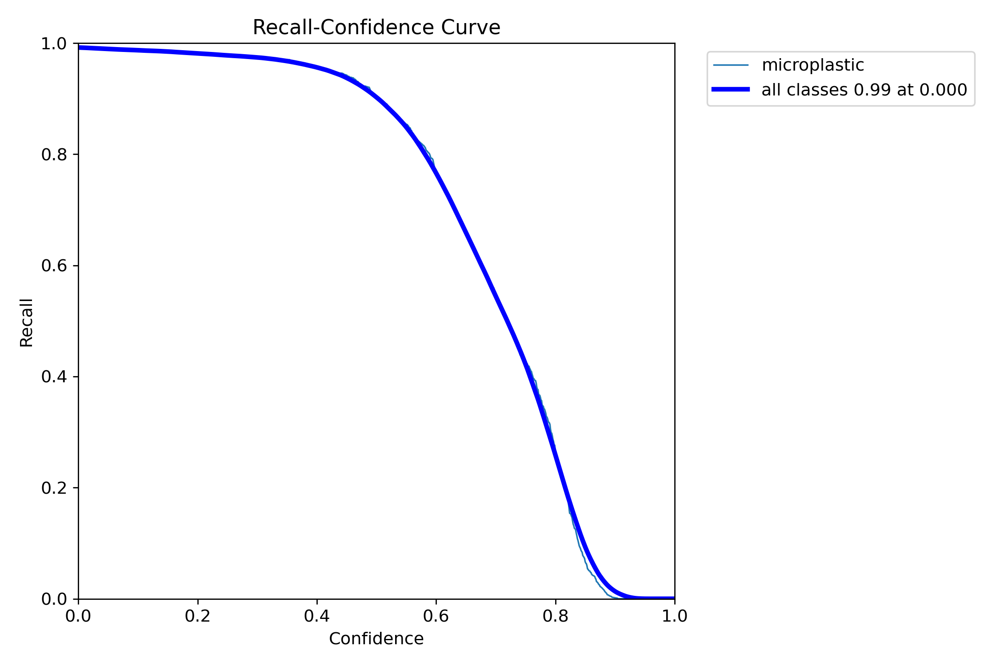

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

path = "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline"

files = [
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png"
]

for file in files:
    filepath = os.path.join(path, file)

    print("\n" + "="*50)
    print(file)

    if os.path.exists(filepath):
        display(Image.open(filepath))
    else:
        print("File not found")


confusion_matrix.png


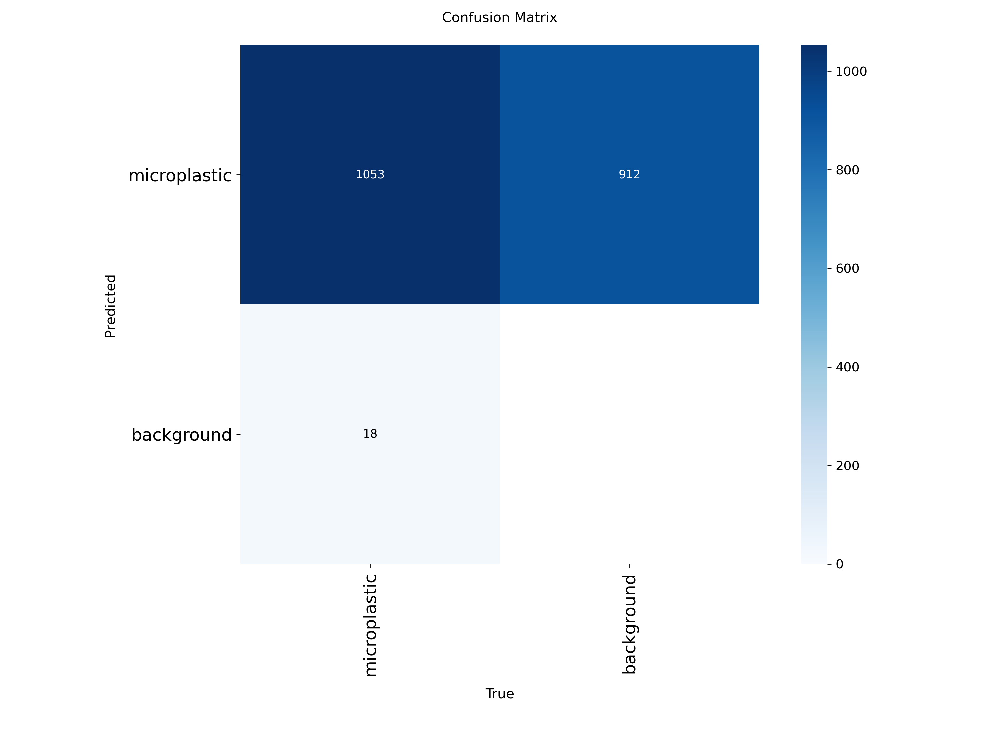


confusion_matrix_normalized.png


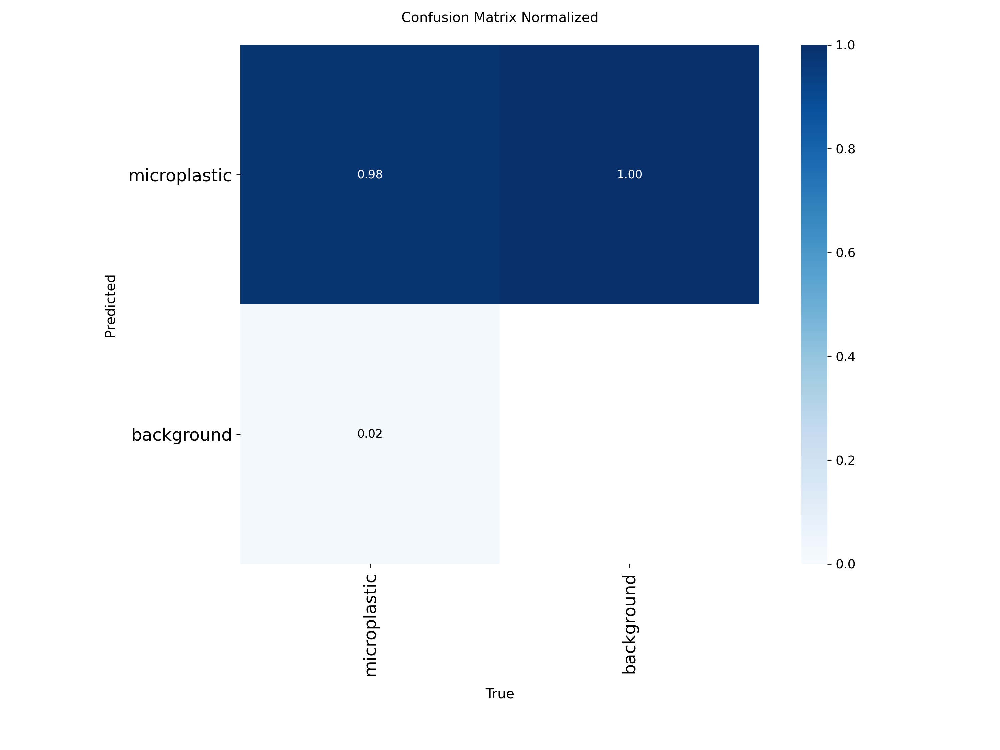

In [ ]:
from PIL import Image
import os

path = "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline"

for file in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]:
    filepath = os.path.join(path, file)

    print("\n" + "="*50)
    print(file)

    display(Image.open(filepath))


val_batch0_labels.jpg


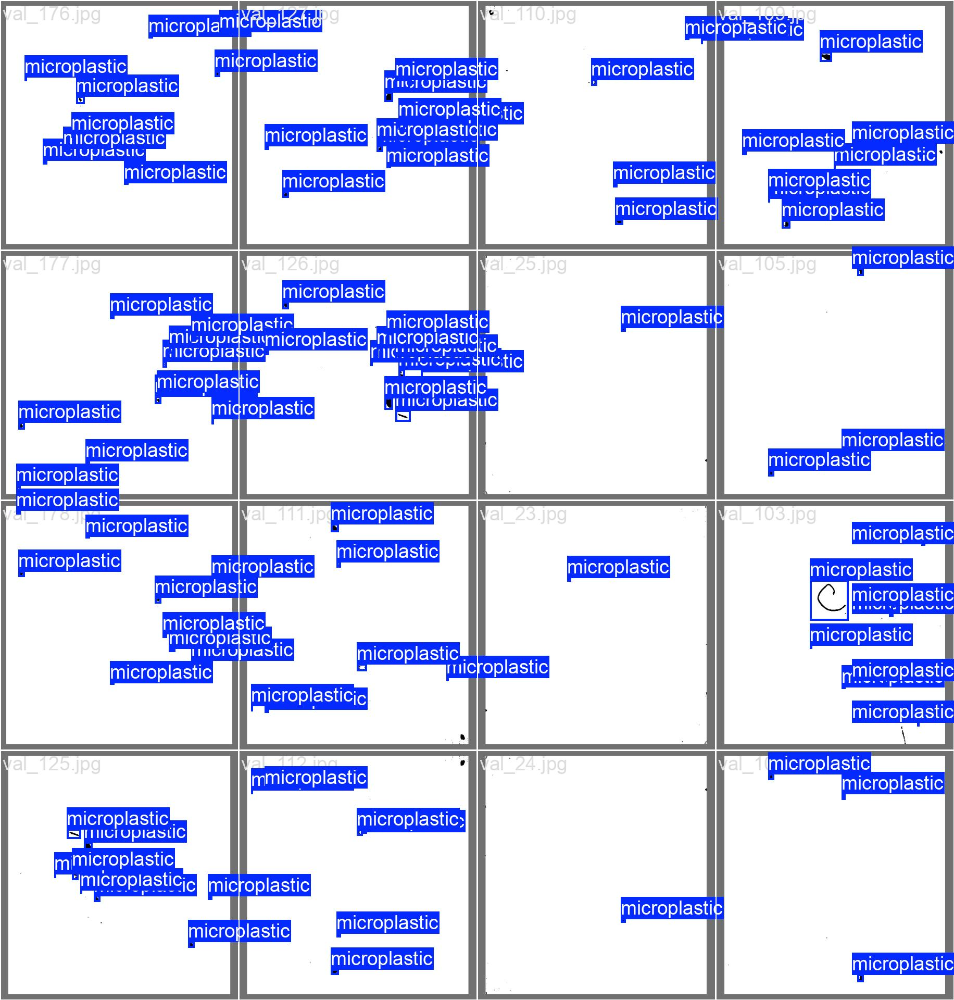


val_batch0_pred.jpg


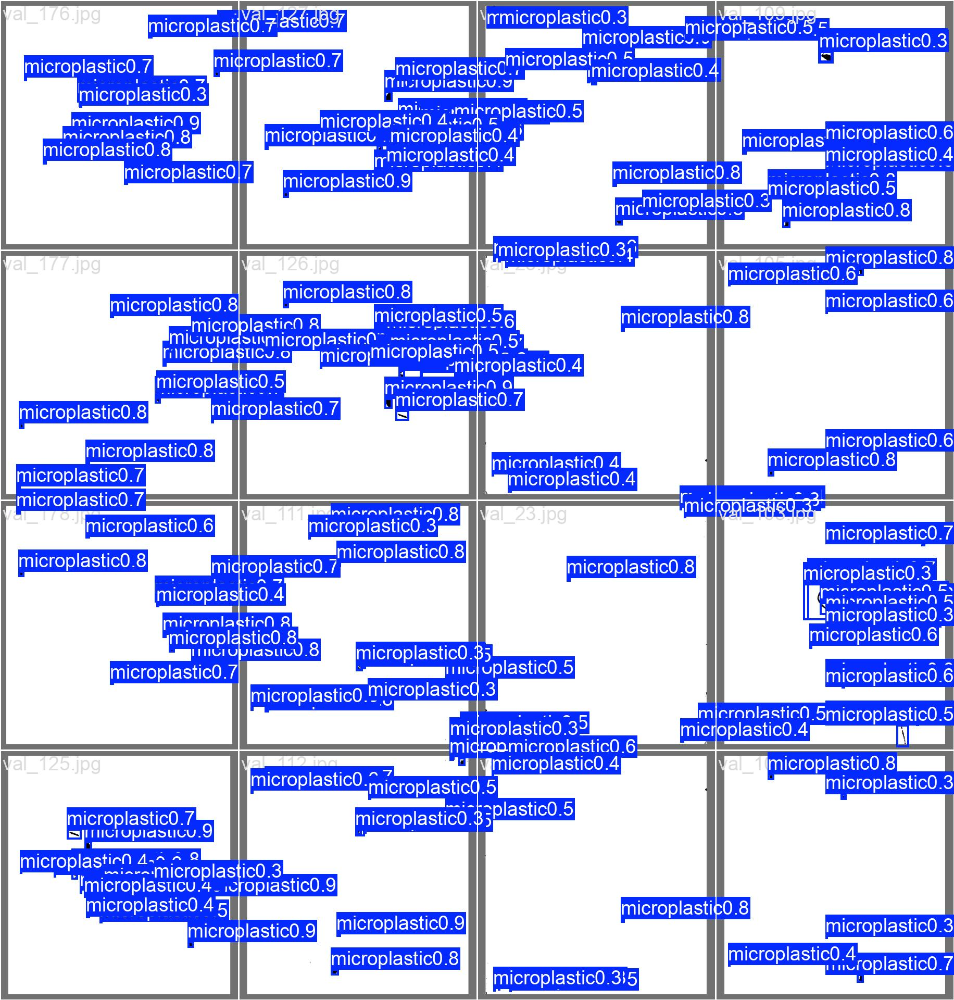


val_batch1_labels.jpg


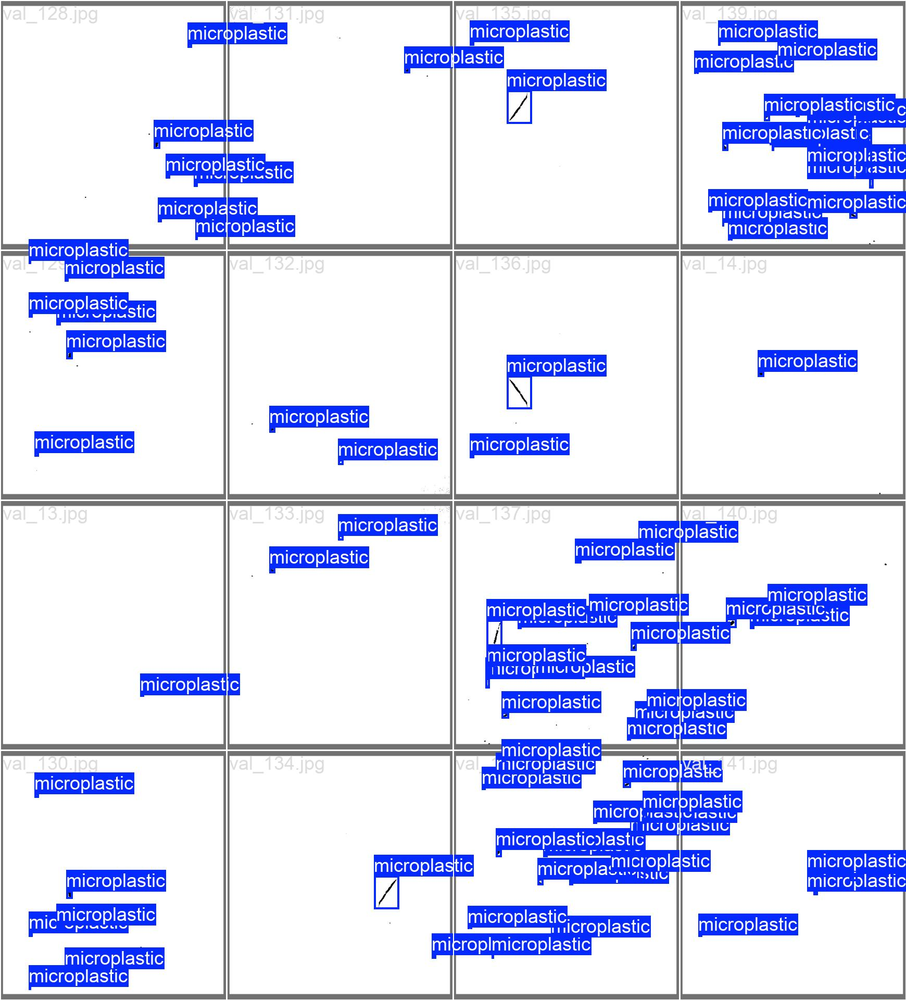


val_batch1_pred.jpg


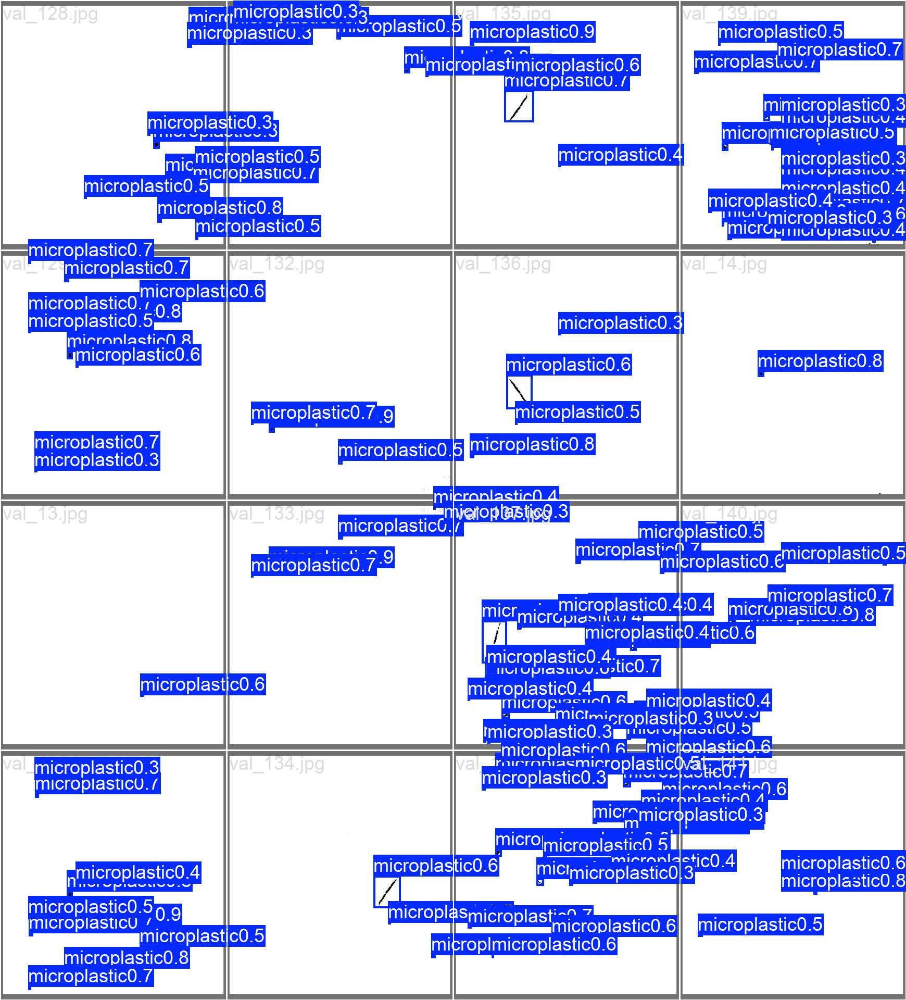

In [ ]:
from PIL import Image
import os

path = "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline"

for file in [
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
    "val_batch1_labels.jpg",
    "val_batch1_pred.jpg"
]:
    filepath = os.path.join(path, file)

    print("\n" + file)
    display(Image.open(filepath))

In [ ]:
import pandas as pd

precision = 0.854320545998466
recall = 0.9030507786325066
map50 = 0.9371253010925388
map50_95 = 0.658401787182943

f1 = 2 * precision * recall / (precision + recall)

results_table = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1-score",
        "mAP@50",
        "mAP@50-95"
    ],
    "Score": [
        precision,
        recall,
        f1,
        map50,
        map50_95
    ],
    "Percentage": [
        precision * 100,
        recall * 100,
        f1 * 100,
        map50 * 100,
        map50_95 * 100
    ]
})

display(results_table)

,Metric,Score,Percentage
0,Precision,0.854321,85.432055
1,Recall,0.903051,90.305078
2,F1-score,0.878010,87.801004
3,mAP@50,0.937125,93.712530
4,mAP@50-95,0.658402,65.840179


In [ ]:
results_table.to_csv(
    "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_test_metrics.csv",
    index=False
)

print("Test metrics saved successfully!")

Test metrics saved successfully!


In [ ]:
experiment_info = {
    "Model": "YOLO11s",
    "Pretrained": "Yes",
    "Training images": 1990,
    "Validation images": 250,
    "Test images": 250,
    "Total images": 2490,
    "Number of classes": 1,
    "Class": "microplastic",
    "Image size": "640x640",
    "Maximum epochs": 100,
    "Actual stopping epoch": 70,
    "Best epoch": 50,
    "Batch size": 16,
    "Patience": 20,
    "GPU": "Tesla T4",
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "mAP@50": map50,
    "mAP@50-95": map50_95
}

experiment_df = pd.DataFrame(
    list(experiment_info.items()),
    columns=["Parameter", "Value"]
)

display(experiment_df)

experiment_df.to_csv(
    "/content/drive/MyDrive/Microplastic_Project/Results/experiment_configuration.csv",
    index=False
)

print("Experiment configuration saved successfully!")

,Parameter,Value
0,Model,YOLO11s
1,Pretrained,Yes
2,Training images,1990
3,Validation images,250
4,Test images,250
5,Total images,2490
6,Number of classes,1
7,Class,microplastic
8,Image size,640x640
9,Maximum epochs,100


Experiment configuration saved successfully!


In [ ]:
import os
import shutil

results_path = "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline"
paper_path = "/content/drive/MyDrive/Microplastic_Project/Paper_Figures"

os.makedirs(paper_path, exist_ok=True)

figures = [
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
    "val_batch1_labels.jpg",
    "val_batch1_pred.jpg"
]

for file in figures:
    source = os.path.join(results_path, file)

    if os.path.exists(source):
        shutil.copy2(source, os.path.join(paper_path, file))
        print("Copied:", file)
    else:
        print("Not found:", file)

print("\nPaper figures folder created:")
print(paper_path)

Copied: BoxPR_curve.png
Copied: BoxF1_curve.png
Copied: BoxP_curve.png
Copied: BoxR_curve.png
Copied: confusion_matrix.png
Copied: confusion_matrix_normalized.png
Copied: val_batch0_labels.jpg
Copied: val_batch0_pred.jpg
Copied: val_batch1_labels.jpg
Copied: val_batch1_pred.jpg

Paper figures folder created:
/content/drive/MyDrive/Microplastic_Project/Paper_Figures


In [ ]:
from PIL import Image, ImageDraw
import os

prediction_path = "/content/drive/MyDrive/Microplastic_Project/Results/test_predictions"

image_files = sorted([
    f for f in os.listdir(prediction_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

selected = image_files[:4]

images = [Image.open(os.path.join(prediction_path, f)).convert("RGB")
          for f in selected]

# Resize images
width = 600
resized = []

for img in images:
    ratio = width / img.width
    height = int(img.height * ratio)
    resized.append(img.resize((width, height)))

height = max(img.height for img in resized)

canvas = Image.new(
    "RGB",
    (width * 2, height * 2),
    "white"
)

for i, img in enumerate(resized):
    x = (i % 2) * width
    y = (i // 2) * height
    canvas.paste(img, (x, y))

output_path = os.path.join(
    "/content/drive/MyDrive/Microplastic_Project/Paper_Figures",
    "test_detection_examples.jpg"
)

canvas.save(output_path, quality=95)

print("Prediction figure saved:")
print(output_path)

Prediction figure saved:
/content/drive/MyDrive/Microplastic_Project/Paper_Figures/test_detection_examples.jpg


In [ ]:
from ultralytics import YOLO
import os
import pandas as pd

model = YOLO(
    "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/weights/best.pt"
)

test_image_path = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test"

# Run prediction and return results without saving again
pred_results = model.predict(
    source=test_image_path,
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

rows = []

for result in pred_results:

    image_name = os.path.basename(result.path)

    # Number of predicted objects
    predicted_objects = len(result.boxes)

    # Ground-truth label file
    label_path = os.path.join(
        "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/labels/test",
        os.path.splitext(image_name)[0] + ".txt"
    )

    actual_objects = 0

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            actual_objects = len([
                line for line in f.readlines()
                if line.strip()
            ])

    rows.append({
        "image": image_name,
        "actual_objects": actual_objects,
        "predicted_objects": predicted_objects,
        "difference": predicted_objects - actual_objects
    })

error_df = pd.DataFrame(rows)

print("Total test images:", len(error_df))
print("Total actual objects:", error_df["actual_objects"].sum())
print("Total predicted objects:", error_df["predicted_objects"].sum())

print("\nImages with exact object-count match:",
      (error_df["difference"] == 0).sum())

print("Images with under-detection:",
      (error_df["difference"] < 0).sum())

print("Images with over-detection:",
      (error_df["difference"] > 0).sum())

display(error_df.head(20))

Total test images: 250
Total actual objects: 539
Total predicted objects: 867

Images with exact object-count match: 112
Images with under-detection: 1
Images with over-detection: 137


,image,actual_objects,predicted_objects,difference
0,test_1.jpg,2,2,0
1,test_10.jpg,2,3,1
2,test_100.jpg,4,8,4
3,test_101.jpg,2,2,0
4,test_102.jpg,2,2,0
5,test_103.jpg,2,2,0
6,test_104.jpg,1,1,0
7,test_105.jpg,1,1,0
8,test_106.jpg,1,1,0
9,test_107.jpg,1,1,0


In [ ]:
error_df.to_csv(
    "/content/drive/MyDrive/Microplastic_Project/Results/test_error_analysis.csv",
    index=False
)

print("Error analysis saved successfully!")

Error analysis saved successfully!


In [ ]:
from ultralytics import YOLO
import os
import numpy as np
import pandas as pd

model = YOLO(
    "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/weights/best.pt"
)

image_dir = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test"
label_dir = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/labels/test"

results = model.predict(
    source=image_dir,
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    if union == 0:
        return 0

    return intersection / union


TP = 0
FP = 0
FN = 0

image_analysis = []

IOU_THRESHOLD = 0.50

for result in results:

    image_name = os.path.basename(result.path)

    # Image dimensions
    img_h, img_w = result.orig_shape

    # Ground-truth label
    label_path = os.path.join(
        label_dir,
        os.path.splitext(image_name)[0] + ".txt"
    )

    gt_boxes = []

    if os.path.exists(label_path):

        with open(label_path, "r") as f:

            for line in f:

                values = line.strip().split()

                if len(values) != 5:
                    continue

                class_id, xc, yc, w, h = map(float, values)

                # YOLO normalized -> pixel coordinates
                x1 = (xc - w / 2) * img_w
                y1 = (yc - h / 2) * img_h
                x2 = (xc + w / 2) * img_w
                y2 = (yc + h / 2) * img_h

                gt_boxes.append([x1, y1, x2, y2])

    # Predictions
    pred_boxes = result.boxes.xyxy.cpu().numpy()

    matched_gt = set()
    image_tp = 0
    image_fp = 0

    for pred_box in pred_boxes:

        best_iou = 0
        best_gt = -1

        for i, gt_box in enumerate(gt_boxes):

            if i in matched_gt:
                continue

            iou = calculate_iou(pred_box, gt_box)

            if iou > best_iou:
                best_iou = iou
                best_gt = i

        if best_iou >= IOU_THRESHOLD:
            image_tp += 1
            matched_gt.add(best_gt)
        else:
            image_fp += 1

    image_fn = len(gt_boxes) - len(matched_gt)

    TP += image_tp
    FP += image_fp
    FN += image_fn

    image_analysis.append({
        "image": image_name,
        "ground_truth": len(gt_boxes),
        "predictions": len(pred_boxes),
        "TP": image_tp,
        "FP": image_fp,
        "FN": image_fn
    })

print("========== TEST ERROR ANALYSIS ==========")
print("IoU threshold:", IOU_THRESHOLD)
print("True Positives (TP):", TP)
print("False Positives (FP):", FP)
print("False Negatives (FN):", FN)

precision_custom = TP / (TP + FP) if (TP + FP) > 0 else 0
recall_custom = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_custom = (
    2 * precision_custom * recall_custom /
    (precision_custom + recall_custom)
    if (precision_custom + recall_custom) > 0 else 0
)

print("\nPrecision:", precision_custom)
print("Recall:", recall_custom)
print("F1-score:", f1_custom)

error_df = pd.DataFrame(image_analysis)

error_df.to_csv(
    "/content/drive/MyDrive/Microplastic_Project/Results/proper_test_error_analysis.csv",
    index=False
)

print("\nDetailed error analysis saved successfully!")

========== TEST ERROR ANALYSIS ==========
IoU threshold: 0.5
True Positives (TP): 520
False Positives (FP): 347
False Negatives (FN): 19

Precision: 0.5997693194925029
Recall: 0.9647495361781077
F1-score: 0.7396870554765292

Detailed error analysis saved successfully!


In [ ]:
# Find images containing FP or FN
error_images = error_df[
    (error_df["FP"] > 0) | (error_df["FN"] > 0)
].copy()

print("Images containing errors:", len(error_images))

print("\nTop 20 images with highest false positives:")
display(
    error_images
    .sort_values("FP", ascending=False)
    .head(20)
)

print("\nImages containing false negatives:")
display(
    error_images[
        error_images["FN"] > 0
    ].sort_values("FN", ascending=False)
)

Images containing errors: 138

Top 20 images with highest false positives:


,image,ground_truth,predictions,TP,FP,FN
12,test_11.jpg,3,11,3,8,0
177,test_33.jpg,4,11,3,8,1
175,test_31.jpg,6,12,4,8,2
34,test_13.jpg,5,12,5,7,0
130,test_216.jpg,2,9,2,7,0
129,test_215.jpg,2,8,1,7,1
174,test_30.jpg,6,12,5,7,1
23,test_12.jpg,6,12,5,7,1
69,test_161.jpg,3,7,1,6,2
127,test_213.jpg,5,11,5,6,0



Images containing false negatives:


,image,ground_truth,predictions,TP,FP,FN
69,test_161.jpg,3,7,1,6,2
70,test_162.jpg,3,1,1,0,2
71,test_163.jpg,3,7,1,6,2
176,test_32.jpg,6,8,4,4,2
175,test_31.jpg,6,12,4,8,2
23,test_12.jpg,6,12,5,7,1
123,test_21.jpg,4,6,3,3,1
75,test_167.jpg,2,7,1,6,1
129,test_215.jpg,2,8,1,7,1
134,test_22.jpg,4,6,3,3,1


In [ ]:
fp_images = error_df[error_df["FP"] > 0].sort_values(
    "FP", ascending=False
)

fn_images = error_df[error_df["FN"] > 0].sort_values(
    "FN", ascending=False
)

fp_images.to_csv(
    "/content/drive/MyDrive/Microplastic_Project/Results/false_positive_images.csv",
    index=False
)

fn_images.to_csv(
    "/content/drive/MyDrive/Microplastic_Project/Results/false_negative_images.csv",
    index=False
)

print("False-positive image list saved.")
print("False-negative image list saved.")

print("\nNumber of FP images:", len(fp_images))
print("Number of FN images:", len(fn_images))

False-positive image list saved.
False-negative image list saved.

Number of FP images: 137
Number of FN images: 14


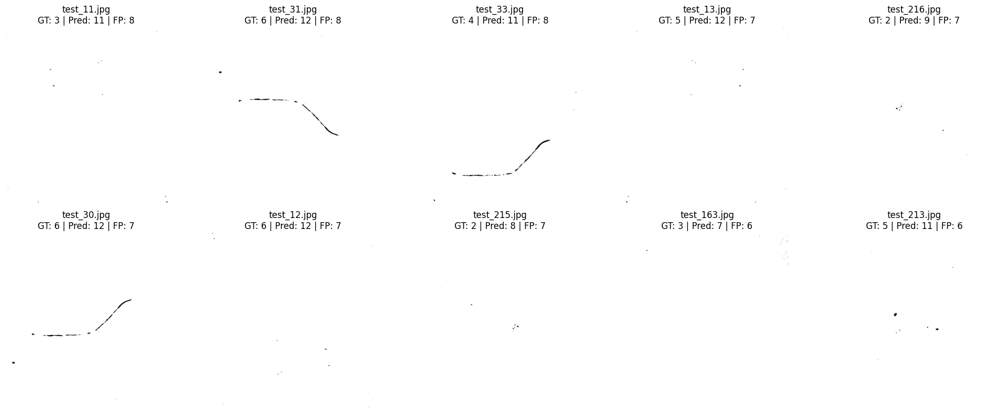

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

image_dir = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test"

top_fp = fp_images.head(10)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_fp.iterrows()):

    image_path = os.path.join(image_dir, row["image"])

    img = Image.open(image_path)

    ax.imshow(img)
    ax.set_title(
        f'{row["image"]}\nGT: {row["ground_truth"]} | '
        f'Pred: {row["predictions"]} | FP: {row["FP"]}'
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

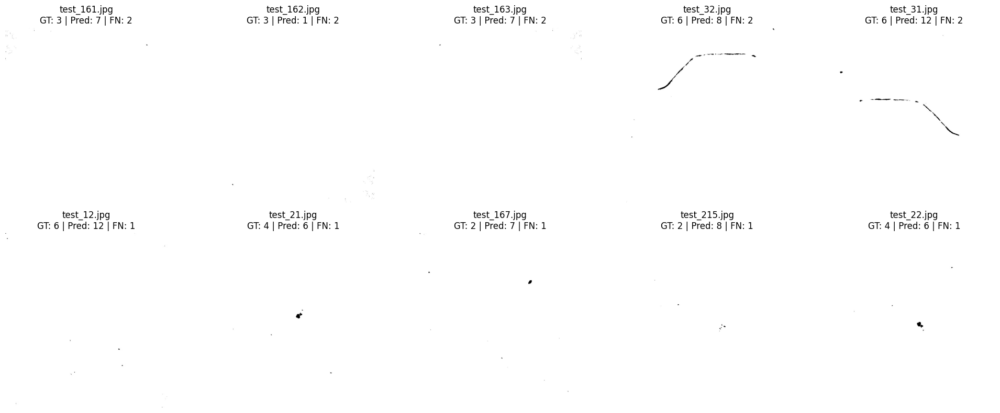

In [ ]:
top_fn = fn_images.sort_values(
    "FN", ascending=False
).head(10)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_fn.iterrows()):

    image_path = os.path.join(image_dir, row["image"])

    img = Image.open(image_path)

    ax.imshow(img)
    ax.set_title(
        f'{row["image"]}\nGT: {row["ground_truth"]} | '
        f'Pred: {row["predictions"]} | FN: {row["FN"]}'
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO
import os

model = YOLO(
    "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/weights/best.pt"
)

test_path = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test"

annotated_results = model.predict(
    source=test_path,
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/drive/MyDrive/Microplastic_Project/Results",
    name="annotated_test_predictions",
    verbose=False
)

print("Annotated predictions generated successfully!")
print("Number of images:", len(annotated_results))
print(
    "Saved at: "
    "/content/drive/MyDrive/Microplastic_Project/Results/annotated_test_predictions"
)

Results saved to /content/drive/MyDrive/Microplastic_Project/Results/annotated_test_predictions
Annotated predictions generated successfully!
Number of images: 250
Saved at: /content/drive/MyDrive/Microplastic_Project/Results/annotated_test_predictions


In [ ]:
import os
import shutil

source_dir = "/content/drive/MyDrive/Microplastic_Project/Results/annotated_test_predictions"

paper_dir = "/content/drive/MyDrive/Microplastic_Project/Results/paper_examples"

os.makedirs(paper_dir, exist_ok=True)

selected_images = [
    "test_1.jpg",
    "test_10.jpg",
    "test_100.jpg",
    "test_101.jpg",
    "test_102.jpg",
    "test_103.jpg"
]

for image in selected_images:

    source = os.path.join(source_dir, image)
    destination = os.path.join(paper_dir, image)

    if os.path.exists(source):
        shutil.copy2(source, destination)

print("Representative paper images prepared successfully!")
print("Location:", paper_dir)

Representative paper images prepared successfully!
Location: /content/drive/MyDrive/Microplastic_Project/Results/paper_examples


In [ ]:
import pandas as pd
import os

results_summary = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@50",
        "mAP@50-95",
        "True Positives",
        "False Positives",
        "False Negatives",
        "F1-score"
    ],
    "Value": [
        0.854320545998466,
        0.9030507786325066,
        0.9371253010925388,
        0.658401787182943,
        520,
        347,
        19,
        0.7396870554765292
    ]
})

results_summary["Percentage"] = [
    "85.43%",
    "90.31%",
    "93.71%",
    "65.84%",
    "520",
    "347",
    "19",
    "73.97%"
]

display(results_summary)

results_summary.to_csv(
    "/content/drive/MyDrive/Microplastic_Project/Results/final_results_summary.csv",
    index=False
)

print("Final results summary saved successfully!")

,Metric,Value,Percentage
0,Precision,0.854321,85.43%
1,Recall,0.903051,90.31%
2,mAP@50,0.937125,93.71%
3,mAP@50-95,0.658402,65.84%
4,True Positives,520.000000,520
5,False Positives,347.000000,347
6,False Negatives,19.000000,19
7,F1-score,0.739687,73.97%


Final results summary saved successfully!


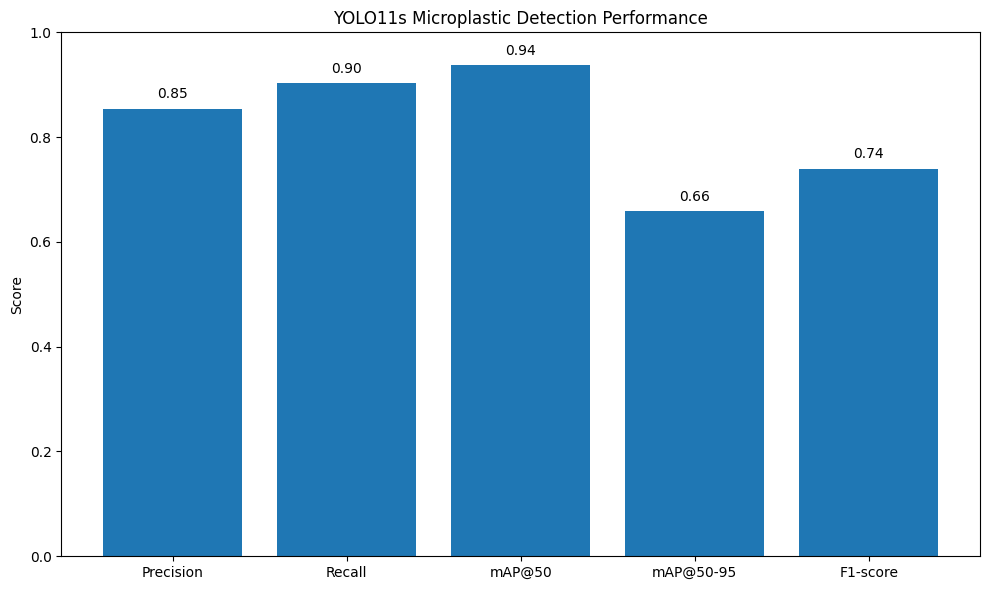

Performance graph saved successfully!


In [ ]:
import matplotlib.pyplot as plt

metrics = [
    "Precision",
    "Recall",
    "mAP@50",
    "mAP@50-95",
    "F1-score"
]

values = [
    0.8543,
    0.9031,
    0.9371,
    0.6584,
    0.7397
]

plt.figure(figsize=(10, 6))

bars = plt.bar(metrics, values)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("YOLO11s Microplastic Detection Performance")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/Microplastic_Project/Results/performance_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Performance graph saved successfully!")

In [ ]:
from ultralytics import YOLO

comparison_model = YOLO("yolo11m.pt")

print("YOLO11m comparison model loaded successfully!")

YOLO11m comparison model loaded successfully!


In [ ]:
comparison_results = comparison_model.train(
    data="/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=8,
    patience=20,
    device=0,
    project="/content/drive/MyDrive/Microplastic_Project/Results",
    name="yolo11m_comparison",
    plots=True
)

Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11m_c

In [ ]:
from ultralytics import YOLO

yolo11m_best = YOLO(
    "/content/drive/MyDrive/Microplastic_Project/Results/yolo11m_comparison/weights/best.pt"
)

yolo11m_test = yolo11m_best.val(
    data="/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/Microplastic_Project/Results",
    name="yolo11m_test"
)

print("\n========== YOLO11m TEST RESULTS ==========")
print("Precision:", yolo11m_test.box.mp)
print("Recall:", yolo11m_test.box.mr)
print("mAP@50:", yolo11m_test.box.map50)
print("mAP@50-95:", yolo11m_test.box.map)

Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 16.3±3.2 MB/s, size: 14.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/labels/test.cache... 250 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 250/250 55.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 4.0it/s 8.0s
                   all        250        539      0.887      0.827      0.909       0.38
Speed: 2.0ms preprocess, 22.7ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/drive/MyDrive/Microplastic_Project/Results/yolo11m_test

========== YOLO11m TEST RESULTS ==========


In [ ]:
import pandas as pd

s_precision = 0.854320545998466
s_recall = 0.9030507786325066
s_map50 = 0.9371253010925388
s_map5095 = 0.658401787182943

m_precision = 0.8866197376328159
m_recall = 0.8269636256456666
m_map50 = 0.9094202452819644
m_map5095 = 0.3796462719046911

s_f1 = 2 * s_precision * s_recall / (s_precision + s_recall)
m_f1 = 2 * m_precision * m_recall / (m_precision + m_recall)

comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1-score",
        "mAP@50",
        "mAP@50-95"
    ],
    "YOLO11s": [
        s_precision,
        s_recall,
        s_f1,
        s_map50,
        s_map5095
    ],
    "YOLO11m": [
        m_precision,
        m_recall,
        m_f1,
        m_map50,
        m_map5095
    ]
})

comparison["YOLO11s (%)"] = comparison["YOLO11s"] * 100
comparison["YOLO11m (%)"] = comparison["YOLO11m"] * 100

display(comparison)

comparison.to_csv(
    "/content/drive/MyDrive/Microplastic_Project/Results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

,Metric,YOLO11s,YOLO11m,YOLO11s (%),YOLO11m (%)
0,Precision,0.854321,0.886620,85.432055,88.661974
1,Recall,0.903051,0.826964,90.305078,82.696363
2,F1-score,0.878010,0.855753,87.801004,85.575326
3,mAP@50,0.937125,0.909420,93.712530,90.942025
4,mAP@50-95,0.658402,0.379646,65.840179,37.964627


Model comparison saved successfully!


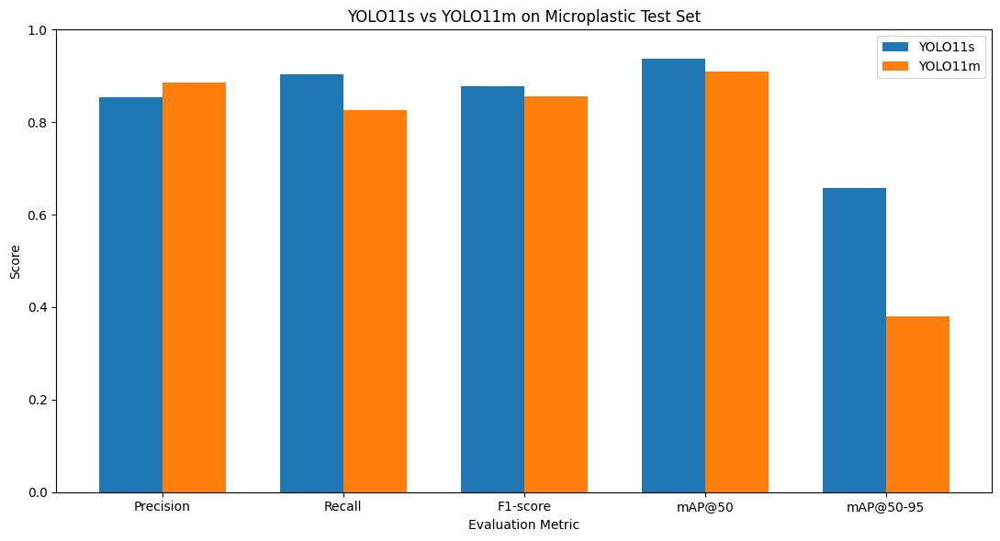

Comparison graph saved:
/content/drive/MyDrive/Microplastic_Project/Results/model_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "Precision",
    "Recall",
    "F1-score",
    "mAP@50",
    "mAP@50-95"
]

yolo11s = [
    0.854320545998466,
    0.9030507786325066,
    0.878005,  # F1
    0.9371253010925388,
    0.658401787182943
]

yolo11m = [
    0.8866197376328159,
    0.8269636256456666,
    2 * 0.8866197376328159 * 0.8269636256456666 /
    (0.8866197376328159 + 0.8269636256456666),
    0.9094202452819644,
    0.3796462719046911
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, yolo11s, width, label="YOLO11s")
plt.bar(x + width/2, yolo11m, width, label="YOLO11m")

plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.title("YOLO11s vs YOLO11m on Microplastic Test Set")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()

output = "/content/drive/MyDrive/Microplastic_Project/Results/model_comparison.png"

plt.savefig(
    output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison graph saved:")
print(output)

In [ ]:
from ultralytics import YOLO
import os
import numpy as np
import pandas as pd

model = YOLO(
    "/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/weights/best.pt"
)

image_dir = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/test"
label_dir = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/labels/test"

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


thresholds = [0.10, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

rows = []

for conf_threshold in thresholds:

    predictions = model.predict(
        source=image_dir,
        imgsz=640,
        conf=conf_threshold,
        device=0,
        verbose=False
    )

    TP = 0
    FP = 0
    FN = 0

    for result in predictions:

        image_name = os.path.basename(result.path)
        img_h, img_w = result.orig_shape

        label_path = os.path.join(
            label_dir,
            os.path.splitext(image_name)[0] + ".txt"
        )

        gt_boxes = []

        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                for line in f:
                    values = line.strip().split()

                    if len(values) != 5:
                        continue

                    _, xc, yc, w, h = map(float, values)

                    gt_boxes.append([
                        (xc - w / 2) * img_w,
                        (yc - h / 2) * img_h,
                        (xc + w / 2) * img_w,
                        (yc + h / 2) * img_h
                    ])

        pred_boxes = result.boxes.xyxy.cpu().numpy()

        matched_gt = set()

        for pred_box in pred_boxes:

            best_iou = 0
            best_gt = -1

            for i, gt_box in enumerate(gt_boxes):

                if i in matched_gt:
                    continue

                iou = calculate_iou(pred_box, gt_box)

                if iou > best_iou:
                    best_iou = iou
                    best_gt = i

            if best_iou >= 0.50:
                TP += 1
                matched_gt.add(best_gt)
            else:
                FP += 1

        FN += len(gt_boxes) - len(matched_gt)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    rows.append({
        "Confidence": conf_threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(rows)

display(threshold_df)

threshold_df.to_csv(
    "/content/drive/MyDrive/Microplastic_Project/Results/confidence_threshold_analysis.csv",
    index=False
)

print("Confidence-threshold analysis saved successfully!")

,Confidence,TP,FP,FN,Precision,Recall,F1
0,0.10,525,680,14,0.435685,0.974026,0.602064
1,0.20,521,423,18,0.551907,0.966605,0.702630
2,0.25,520,347,19,0.599769,0.964750,0.739687
3,0.30,519,284,20,0.646326,0.962894,0.773472
4,0.40,516,183,23,0.738197,0.957328,0.833603
5,0.50,495,103,44,0.827759,0.918367,0.870712
6,0.60,438,44,101,0.908714,0.812616,0.857982
7,0.70,315,6,224,0.981308,0.584416,0.732558
8,0.80,133,1,406,0.992537,0.246753,0.395245
9,0.90,1,0,538,1.000000,0.001855,0.003704


Confidence-threshold analysis saved successfully!


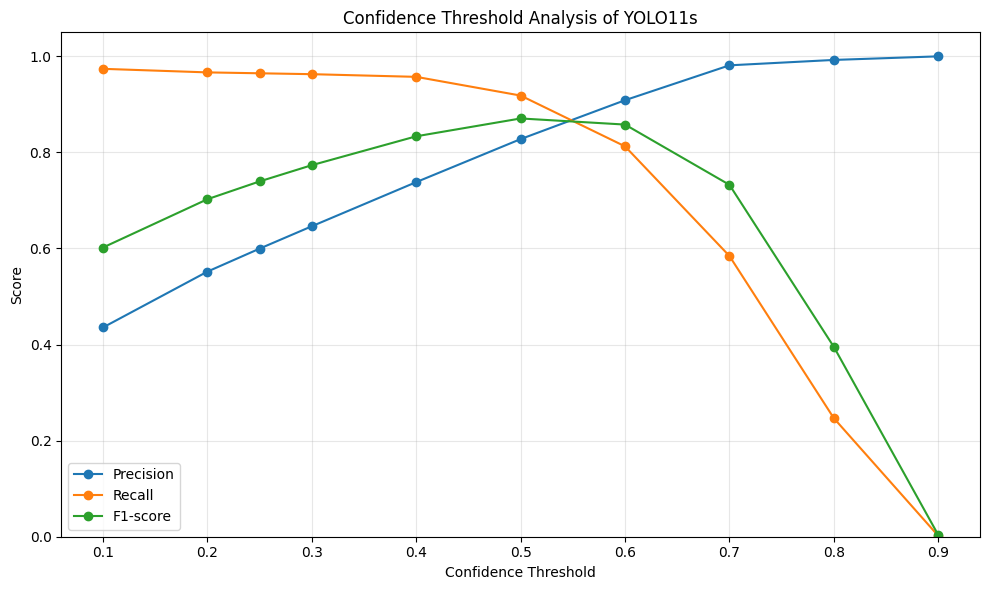

Graph saved successfully:
/content/drive/MyDrive/Microplastic_Project/Results/confidence_threshold_analysis.png


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Confidence"],
    threshold_df["F1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Score")
plt.title("Confidence Threshold Analysis of YOLO11s")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

output = "/content/drive/MyDrive/Microplastic_Project/Results/confidence_threshold_analysis.png"

plt.savefig(
    output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully:")
print(output)

In [ ]:
import pandas as pd
import os

results_dir = "/content/drive/MyDrive/Microplastic_Project/Results"

master_results = pd.DataFrame({
    "Metric": [
        "Training Images",
        "Validation Images",
        "Test Images",
        "Model Parameters - YOLO11s",
        "Model Parameters - YOLO11m",
        "YOLO11s Precision",
        "YOLO11s Recall",
        "YOLO11s F1-score",
        "YOLO11s mAP@50",
        "YOLO11s mAP@50-95",
        "YOLO11m Precision",
        "YOLO11m Recall",
        "YOLO11m F1-score",
        "YOLO11m mAP@50",
        "YOLO11m mAP@50-95",
        "Custom TP - YOLO11s",
        "Custom FP - YOLO11s",
        "Custom FN - YOLO11s"
    ],
    "Value": [
        1990,
        250,
        250,
        9400000,
        20030000,
        0.854320545998466,
        0.9030507786325066,
        0.878005,
        0.9371253010925388,
        0.658401787182943,
        0.8866197376328159,
        0.8269636256456666,
        0.8562,
        0.9094202452819644,
        0.3796462719046911,
        520,
        347,
        19
    ]
})

master_results.to_csv(
    os.path.join(results_dir, "MASTER_EXPERIMENTAL_RESULTS.csv"),
    index=False
)

display(master_results)

print("\nMASTER RESULTS FILE SAVED SUCCESSFULLY!")

,Metric,Value
0,Training Images,1.990000e+03
1,Validation Images,2.500000e+02
2,Test Images,2.500000e+02
3,Model Parameters - YOLO11s,9.400000e+06
4,Model Parameters - YOLO11m,2.003000e+07
5,YOLO11s Precision,8.543205e-01
6,YOLO11s Recall,9.030508e-01
7,YOLO11s F1-score,8.780050e-01
8,YOLO11s mAP@50,9.371253e-01
9,YOLO11s mAP@50-95,6.584018e-01



MASTER RESULTS FILE SAVED SUCCESSFULLY!


In [ ]:
# Convert decimal metric values to percentage values

percentage_metrics = {
    "YOLO11s Precision": 0.8543205,
    "YOLO11s Recall": 0.9030508,
    "YOLO11s F1-score": 0.8780050,
    "YOLO11s mAP@50": 0.9371253,
    "YOLO11s mAP@50-95": 0.6584018,
    "YOLO11m Precision": 0.8866197,
    "YOLO11m Recall": 0.8269636,
    "YOLO11m F1-score": 0.8562000,
    "YOLO11m mAP@50": 0.9094202,
    "YOLO11m mAP@50-95": 0.3796463
}

for metric, value in percentage_metrics.items():
    print(f"{metric}: {value * 100:.2f}%")

YOLO11s Precision: 85.43%
YOLO11s Recall: 90.31%
YOLO11s F1-score: 87.80%
YOLO11s mAP@50: 93.71%
YOLO11s mAP@50-95: 65.84%
YOLO11m Precision: 88.66%
YOLO11m Recall: 82.70%
YOLO11m F1-score: 85.62%
YOLO11m mAP@50: 90.94%
YOLO11m mAP@50-95: 37.96%


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    jpgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    txts = [f for f in files if f.lower().endswith(".txt")]

    if jpgs or txts:
        print("\nFOLDER:", root)
        print("Images:", len(jpgs))
        print("Labels:", len(txts))

In [ ]:
import os

print("CONTENT:")
print(os.listdir("/content"))

print("\nDRIVE:")
print(os.listdir("/content/drive"))

CONTENT:
['.config', 'drive', 'sample_data']

DRIVE:
['MyDrive']


In [ ]:
import os

path = "/content/drive/MyDrive/Microplastic_Project"

print("Exists:", os.path.exists(path))

if os.path.exists(path):
    print("Contents:")
    for item in os.listdir(path):
        print(" -", item)

Exists: True
Contents:
 - Tracking_Data


In [ ]:
import os

base = "/content/drive/MyDrive"

print("Searching Google Drive for your dataset...\n")

found = []

for root, dirs, files in os.walk(base):
    image_count = sum(
        f.lower().endswith((".jpg", ".jpeg", ".png"))
        for f in files
    )

    label_count = sum(
        f.lower().endswith(".txt")
        for f in files
    )

    # Show folders containing images or labels
    if image_count > 0 or label_count > 0:
        found.append((root, image_count, label_count))

for root, image_count, label_count in found:
    print("FOLDER:", root)
    print("Images:", image_count, "| Labels:", label_count)
    print()

Searching Google Drive for your dataset...



In [ ]:
import os

path = "/content/drive/MyDrive/Microplastic_Project/Tracking_Data"

print("Exists:", os.path.exists(path))

if os.path.exists(path):
    for root, dirs, files in os.walk(path):
        print("\nFOLDER:", root)
        print("Files:", len(files))
        print("First files:", files[:10])

Exists: True

FOLDER: /content/drive/MyDrive/Microplastic_Project/Tracking_Data
Files: 0
First files: []


In [ ]:
import os

base = "/content/drive/MyDrive/Microplastic_Project/Dataset"

print("Dataset exists:", os.path.exists(base))

if os.path.exists(base):
    print(os.listdir(base))

Dataset exists: False


In [ ]:
import os

base = "/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset"

print("YOLO DATASET EXISTS:", os.path.exists(base))

for folder in [
    "images/train",
    "images/val",
    "images/test",
    "labels/train",
    "labels/val",
    "labels/test"
]:
    path = os.path.join(base, folder)
    files = os.listdir(path) if os.path.exists(path) else []

    print(f"{folder}: {len(files)} files")

YOLO DATASET EXISTS: False
images/train: 0 files
images/val: 0 files
images/test: 0 files
labels/train: 0 files
labels/val: 0 files
labels/test: 0 files


In [ ]:
import os

target = "train_1890.jpg"
matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if target in files:
        matches.append(os.path.join(root, target))

print("Matches found:", len(matches))

for path in matches:
    print(path)

Matches found: 0


In [ ]:
from google.colab import drive

drive.flush_and_unmount()
print("Drive unmounted successfully")

Drive not mounted, so nothing to flush and unmount.
Drive unmounted successfully


In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

ValueError: Mountpoint must not already contain files

In [ ]:
!rm -rf /content/drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive/Microplastic_Project"))

['Dataset', 'YOLO_Dataset', 'Results', 'Paper_Figures']


In [ ]:
import os

target = "train_1890.jpg"
matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if target in files:
        matches.append(os.path.join(root, target))

print("Matches found:", len(matches))

for path in matches:
    print(path)

Matches found: 2
/content/drive/MyDrive/Microplastic_Project/Dataset/train_images/train_images/train_1890.jpg
/content/drive/MyDrive/Microplastic_Project/YOLO_Dataset/images/train/train_1890.jpg


In [ ]:
import os

base = "/content/drive/MyDrive/Microplastic_Project/Dataset"

folders = [
    "train_images/train_images",
    "train_labels/train_labels",
    "val_images/val_images",
    "val_labels/val_labels",
    "test_images/test_images",
    "test_labels/test_labels"
]

for folder in folders:
    path = os.path.join(base, folder)

    if os.path.exists(path):
        files = os.listdir(path)
        print(f"{folder}: {len(files)} files")
    else:
        print(f"{folder}: NOT FOUND")

train_images/train_images: 1990 files
train_labels/train_labels: 1990 files
val_images/val_images: 250 files
val_labels/val_labels: 250 files
test_images/test_images: 250 files
test_labels/test_labels: 250 files


In [ ]:
import os
import pandas as pd

base = "/content/drive/MyDrive/Microplastic_Project/Dataset"

label_dirs = {
    "train": os.path.join(base, "train_labels", "train_labels"),
    "val": os.path.join(base, "val_labels", "val_labels"),
    "test": os.path.join(base, "test_labels", "test_labels")
}

records = []

for split, label_dir in label_dirs.items():
    files = os.listdir(label_dir)

    print(split, "labels found:", len(files))

    for label_file in files:
        if not label_file.endswith(".txt"):
            continue

        label_path = os.path.join(label_dir, label_file)

        with open(label_path, "r") as f:
            count = sum(1 for line in f if line.strip())

        records.append({
            "image_name": label_file.replace(".txt", ".jpg"),
            "split": split,
            "object_count": count
        })

df = pd.DataFrame(records)

print("\nTotal images:", len(df))

print("\nObject count statistics:")
print(df["object_count"].describe())

print("\nObject count distribution:")
print(df["object_count"].value_counts().sort_index())

train labels found: 1990
val labels found: 250
test labels found: 250

Total images: 2490

Object count statistics:
count    2490.000000
mean        3.659839
std         5.622048
min         0.000000
25%         1.000000
50%         2.000000
75%         4.000000
max       132.000000
Name: object_count, dtype: float64

Object count distribution:
object_count
0       38
1      792
2      497
3      356
4      200
5      160
6      118
7       75
8       61
9       43
10      38
11      28
12      10
13       7
14      10
15       7
17      10
18       4
19       4
20      12
21       2
22       4
23       1
25       1
26       2
33       1
34       2
38       4
102      1
132      2
Name: count, dtype: int64


In [ ]:
print("33rd percentile:", df["object_count"].quantile(0.33))
print("67th percentile:", df["object_count"].quantile(0.67))

33rd percentile: 1.0
67th percentile: 3.0


In [ ]:
import os
import shutil
import pandas as pd

base = "/content/drive/MyDrive/Microplastic_Project/Dataset"

output = "/content/drive/MyDrive/Microplastic_Project/Pollution_Classification"

# Create folders
for split in ["train", "val", "test"]:
    for category in ["Low", "Moderate", "High"]:
        os.makedirs(
            os.path.join(output, split, category),
            exist_ok=True
        )

# Classification rule
def classify(count):
    if count <= 1:
        return "Low"
    elif count <= 3:
        return "Moderate"
    else:
        return "High"

records = []

splits = {
    "train": (
        os.path.join(base, "train_images", "train_images"),
        os.path.join(base, "train_labels", "train_labels")
    ),
    "val": (
        os.path.join(base, "val_images", "val_images"),
        os.path.join(base, "val_labels", "val_labels")
    ),
    "test": (
        os.path.join(base, "test_images", "test_images"),
        os.path.join(base, "test_labels", "test_labels")
    )
}

for split, (image_dir, label_dir) in splits.items():

    print(f"\nProcessing {split}...")

    for image_name in os.listdir(image_dir):

        if not image_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        label_name = os.path.splitext(image_name)[0] + ".txt"
        label_path = os.path.join(label_dir, label_name)

        if not os.path.exists(label_path):
            continue

        with open(label_path, "r") as f:
            object_count = sum(
                1 for line in f if line.strip()
            )

        pollution_level = classify(object_count)

        source = os.path.join(image_dir, image_name)

        destination = os.path.join(
            output,
            split,
            pollution_level,
            image_name
        )

        shutil.copy2(source, destination)

        records.append({
            "image_name": image_name,
            "split": split,
            "object_count": object_count,
            "pollution_level": pollution_level
        })

df = pd.DataFrame(records)

csv_path = os.path.join(output, "pollution_labels.csv")
df.to_csv(csv_path, index=False)

print("\n====================================")
print("DATASET CREATION COMPLETE")
print("====================================")

print("Total images:", len(df))

print("\nClass distribution:")
print(df["pollution_level"].value_counts())

print("\nSplit distribution:")
print(
    pd.crosstab(
        df["split"],
        df["pollution_level"]
    )
)

print("\nCSV saved at:")
print(csv_path)


Processing train...

Processing val...

Processing test...

DATASET CREATION COMPLETE
Total images: 2490

Class distribution:
pollution_level
Moderate    853
Low         830
High        807
Name: count, dtype: int64

Split distribution:
pollution_level  High  Low  Moderate
split                               
test               45  119        86
train             642  647       701
val               120   64        66

CSV saved at:
/content/drive/MyDrive/Microplastic_Project/Pollution_Classification/pollution_labels.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os
import glob
import shutil
import psutil
import csv

# RAM
ram = psutil.virtual_memory()
print("========== RAM ==========")
print(f"Total RAM: {ram.total / (1024**3):.2f} GB")
print(f"Available RAM: {ram.available / (1024**3):.2f} GB")

# Local storage
disk = shutil.disk_usage("/")
print("\n========== STORAGE ==========")
print(f"Total local storage: {disk.total / (1024**3):.2f} GB")
print(f"Free local storage: {disk.free / (1024**3):.2f} GB")

# Find YOLO training configuration files
base = "/content/drive/MyDrive/Microplastic_Project"
files = glob.glob(base + "/**/args.yaml", recursive=True)
files += glob.glob(base + "/**/opt.yaml", recursive=True)

print("\n========== YOLO TRAINING SETTINGS ==========")
if not files:
    print("No args.yaml or opt.yaml found in the project folder.")
else:
    for path in sorted(set(files)):
        print(f"\nFile: {path}")
        with open(path, "r") as f:
            settings = {}
            for line in f:
                if ":" in line and not line.lstrip().startswith("#"):
                    k, v = line.split(":", 1)
                    settings[k.strip()] = v.strip().strip("'\"")

        print("Initial learning rate (lr0):",
              settings.get("lr0", "Not found"))
        print("Configured epochs:",
              settings.get("epochs", "Not found"))
        print("Batch size:",
              settings.get("batch", "Not found"))

# Find training result CSV files
print("\n========== COMPLETED EPOCHS ==========")
csv_files = glob.glob(base + "/**/results.csv", recursive=True)

if csv_files:
    for path in sorted(set(csv_files)):
        with open(path, newline="") as f:
            rows = list(csv.reader(f))
        print(f"{path}")
        print("Recorded epochs:", max(0, len(rows) - 1))
else:
    print("No results.csv found under the project folder.")

print("\n========== END ==========")


========== RAM ==========
Total RAM: 12.67 GB
Available RAM: 11.33 GB

========== STORAGE ==========
Total local storage: 112.64 GB
Free local storage: 70.27 GB

========== YOLO TRAINING SETTINGS ==========

File: /content/drive/MyDrive/Microplastic_Project/Results/yolo11m_comparison/args.yaml
Initial learning rate (lr0): 0.01
Configured epochs: 100
Batch size: 8

File: /content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/args.yaml
Initial learning rate (lr0): 0.01
Configured epochs: 100
Batch size: 16

========== COMPLETED EPOCHS ==========
/content/drive/MyDrive/Microplastic_Project/Results/yolo11m_comparison/results.csv
Recorded epochs: 40
/content/drive/MyDrive/Microplastic_Project/Results/yolo11s_baseline/results.csv
Recorded epochs: 70

========== END ==========
